# Figure 5 — Q4: does removing the batch term make the downstream answers better?

Differential abundance and cross-study prediction are what correction is for. This figure checks whether 'removes batch well' and 'answers the question well' are the same ranking, and ends with what to actually use.

**Each panel is defined and drawn in its own cell.** Edit the function, re-run that one cell, see the result. The last cell assembles all of them at the submission size (180 x 240 mm) and writes the PDF that goes to the journal.

Run the Setup, Shared helpers and Data cells first; after that the panel cells are independent of each other.

## Setup

In [1]:
# Everything the panels read is relative to benchmark/, so make that the working directory
# whether the notebook was opened from benchmark/ or from benchmark/figures/.
if (basename(getwd()) == "figures") setwd("..")
stopifnot("run this from benchmark/ or benchmark/figures/" = file.exists("config/methods.tsv"))

# _panels.R holds what every figure shares: the method inventory and its ordering, the metric
# catalogue, the two normalisations used for ranking, the theme, and save_figure().
source("figures/_panels.R")

results_dir <- "results"

## Shared helpers

Small pieces more than one panel below needs.

In [2]:
batch_metrics <- function() c("R2_batch_ait", "R2_batch_bc", "R2_batch_jac", "ASW_batch", "iLISI")

bio_metrics <- function() c("R2_pheno_ait", "R2_pheno_bc", "R2_pheno_jac", "ASW_pheno", "cLISI")

# Two truths side by side. "planted" is what the simulation put in; "batch-free answer" is what the
# same test finds on the oracle table -- the answer the data would have given with no batch effect.
# The error rate is pooled over scenarios rather than averaged: most scenarios call only a handful of
# taxa, and a per-scenario ratio with a denominator of one or two is 0 or 1 by arithmetic, not by
# behaviour. Power and precision have no such denominator and keep their distribution.
truth_labels <- function() c(planted = "planted truth", oracle = "batch-free answer")

# The three ways of saying "this method is good", put on one axis each.
ranking_table <- function(scored, loso) {
  evaluated <- scored[scored$status == "ok", ]
  batch <- family_score(evaluated, batch_metrics()) %>% filter(family == "batch") %>%
    select(method, `batch removal` = score)
  da <- evaluated %>% filter(regime == "sim", da_prop > 0) %>% group_by(method) %>%
    summarise(`DA recovery` = mean(DA_oracle_AP, na.rm = TRUE), .groups = "drop")
  prediction <- loso %>% filter(status == "ok") %>% group_by(method) %>%
    summarise(`cross-study auROC` = mean(auroc, na.rm = TRUE), .groups = "drop")
  Reduce(function(a, b) inner_join(a, b, by = "method"), list(batch, da, prediction))
}

## Data

In [3]:
scored <- read_scores(file.path(results_dir, "scores.tsv"))
loso <- read.delim(file.path(results_dir, "loso.tsv"))
simulated <- scored[scored$regime == "sim" & scored$status == "ok", ]
confounding <- dataset_confounding(results_dir, unique(scored$dataset[scored$regime == "real"]))
names(confounding) <- sub("^real/", "", unique(scored$dataset[scored$regime == "real"]))

cat(nrow(loso), "leave-one-study-out folds,", sum(loso$status == "ok"), "scored\n")

1409 leave-one-study-out folds, 1344 scored


## a. Differential abundance against two truths

Orange is what the simulation planted; green is what the same test finds on the batch-free table. The second is reported because planting fold changes renormalises the community, so untouched taxa genuinely shift.

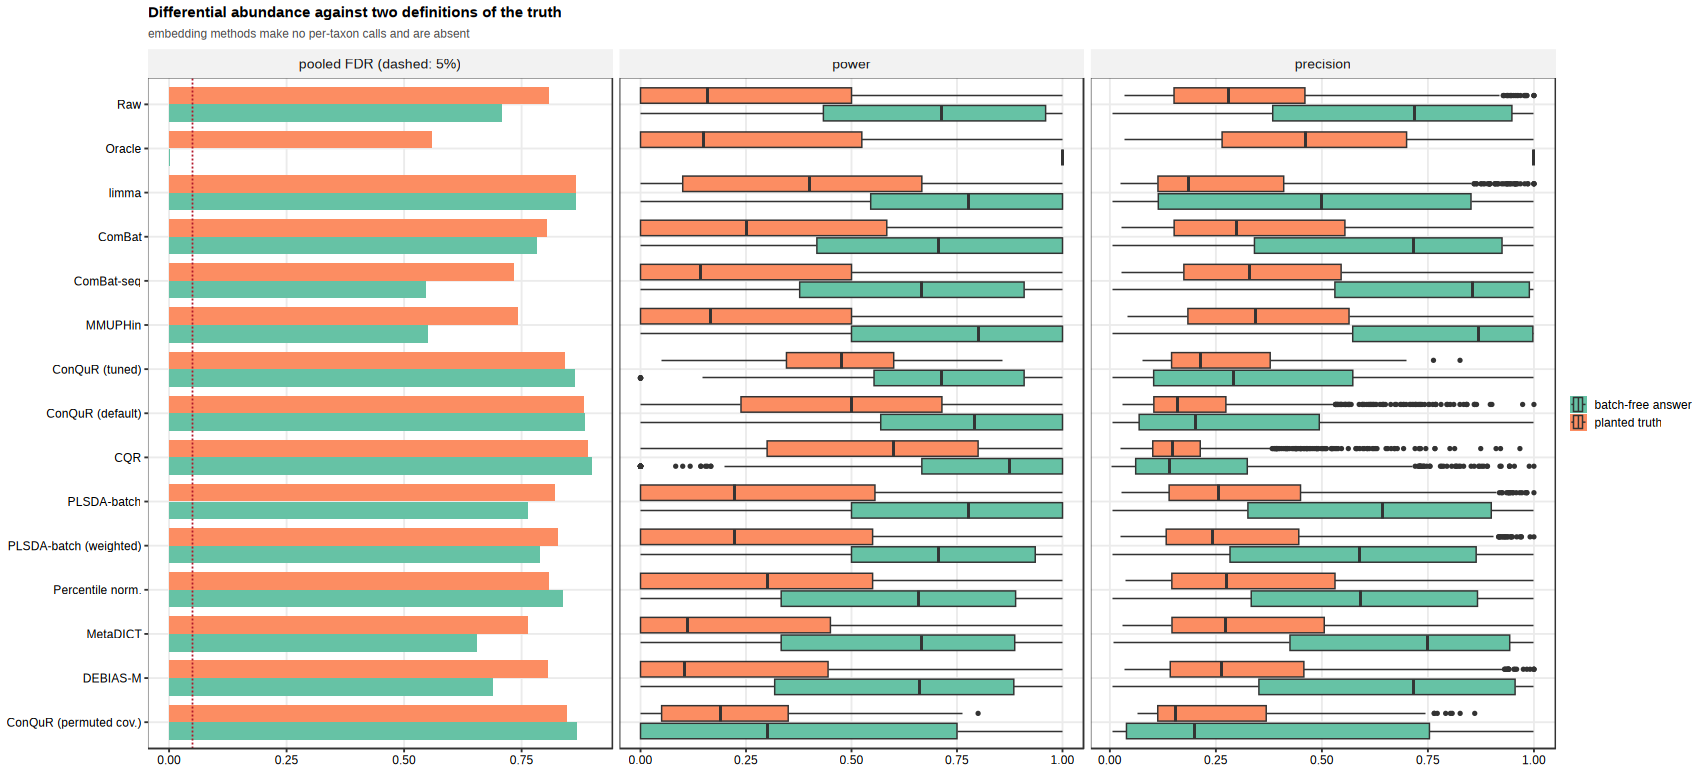

In [4]:
panel_da <- function(planted, methods_table = method_table()) {
  planted <- planted[!is.na(planted$DA_nsig), ]
  measures <- c("pooled FDR (dashed: 5%)", "power", "precision")
  pooled <- bind_rows(
    planted %>% group_by(method) %>%
      summarise(value = sum(DA_FDR * DA_nsig, na.rm = TRUE) / sum(DA_nsig, na.rm = TRUE),
                truth = truth_labels()[["planted"]], .groups = "drop"),
    planted %>% group_by(method) %>%
      summarise(value = sum(DA_oracle_FDR * DA_nsig, na.rm = TRUE) / sum(DA_nsig, na.rm = TRUE),
                truth = truth_labels()[["oracle"]], .groups = "drop"))
  pooled$measure <- factor(measures[1], measures)
  spread <- bind_rows(
    data.frame(method = planted$method, value = planted$DA_power, measure = measures[2],
               truth = truth_labels()[["planted"]]),
    data.frame(method = planted$method, value = planted$DA_oracle_power, measure = measures[2],
               truth = truth_labels()[["oracle"]]),
    data.frame(method = planted$method, value = planted$DA_AP, measure = measures[3],
               truth = truth_labels()[["planted"]]),
    data.frame(method = planted$method, value = planted$DA_oracle_AP, measure = measures[3],
               truth = truth_labels()[["oracle"]]))
  spread$measure <- factor(spread$measure, measures)

  ggplot(mapping = aes(value, label, fill = truth)) +
    geom_col(data = label_methods(pooled, methods_table), position = position_dodge(0.8), width = 0.75) +
    geom_vline(data = data.frame(measure = factor(measures[1], measures)), aes(xintercept = 0.05),
               linetype = "22", linewidth = 0.3, colour = "#b2182b") +
    geom_boxplot(data = label_methods(spread[!is.na(spread$value), ], methods_table),
                 outlier.size = 0.2, linewidth = 0.25, width = 0.7, position = position_dodge(0.8)) +
    facet_wrap(~ measure, nrow = 1, scales = "free_x") +
    scale_fill_brewer(palette = "Set2", name = NULL) +
    scale_y_discrete(limits = rev) +
    labs(x = NULL, y = NULL, title = "Differential abundance against two definitions of the truth",
         subtitle = "embedding methods make no per-taxon calls and are absent") +
    theme_bench() +
    theme(plot.subtitle = element_text(size = 5.5, colour = "grey30"))
}

show_panel(panel_da(simulated[simulated$da_prop > 0, ]), 180, 82)

## b. With nothing planted

Null scenarios: the fraction of taxa each method still calls.

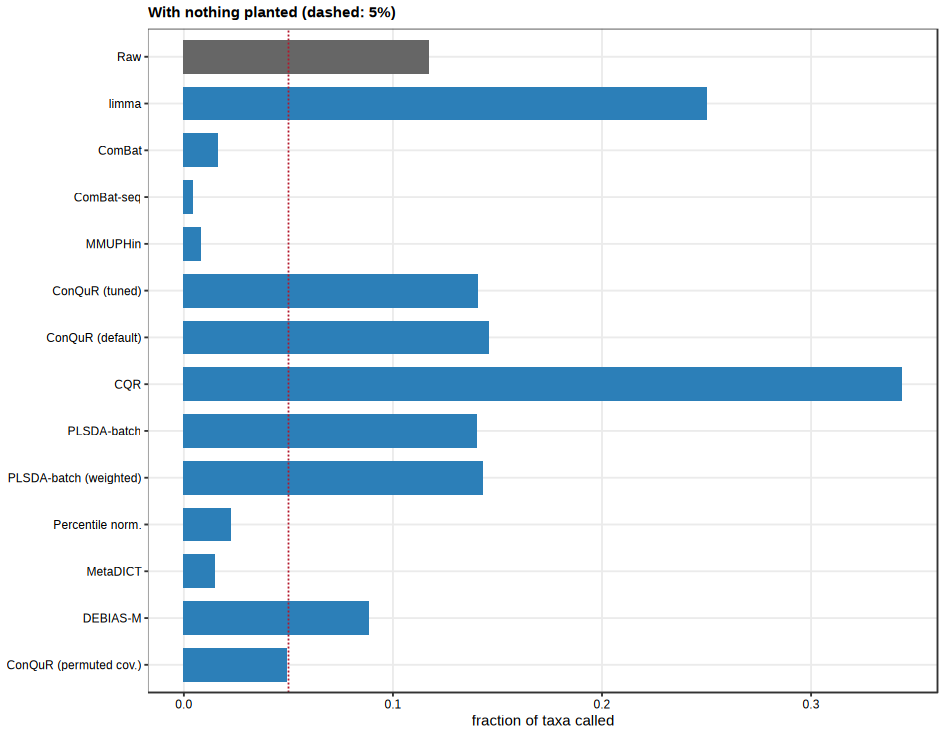

In [5]:
# Embeddings have no taxon axis and make no calls, so they are absent rather than scored as zero.
panel_null_da <- function(null_simulated, methods_table = method_table()) {
  rates <- null_simulated[!is.na(null_simulated$DA_nsig), ] %>%
    group_by(method) %>%
    summarise(false_positives = mean(DA_nsig / n_taxa), .groups = "drop")
  ggplot(label_methods(rates, methods_table), aes(false_positives, label, fill = track)) +
    geom_col(width = 0.7) +
    geom_vline(xintercept = 0.05, linetype = "22", linewidth = 0.3, colour = "#b2182b") +
    scale_fill_manual(values = track_colours(), guide = "none") +
    scale_y_discrete(limits = rev) +
    labs(x = "fraction of taxa called", y = NULL, title = "With nothing planted (dashed: 5%)") +
    theme_bench()
}

show_panel(panel_null_da(simulated[simulated$da_prop == 0 & simulated$method != "oracle", ]), 100, 78)

## c. Cross-study prediction

Leave-one-study-out auROC. An **upper bound**: correction ran once on the whole dataset and saw the held-out labels. `raw` has no leakage and is the honest reference.

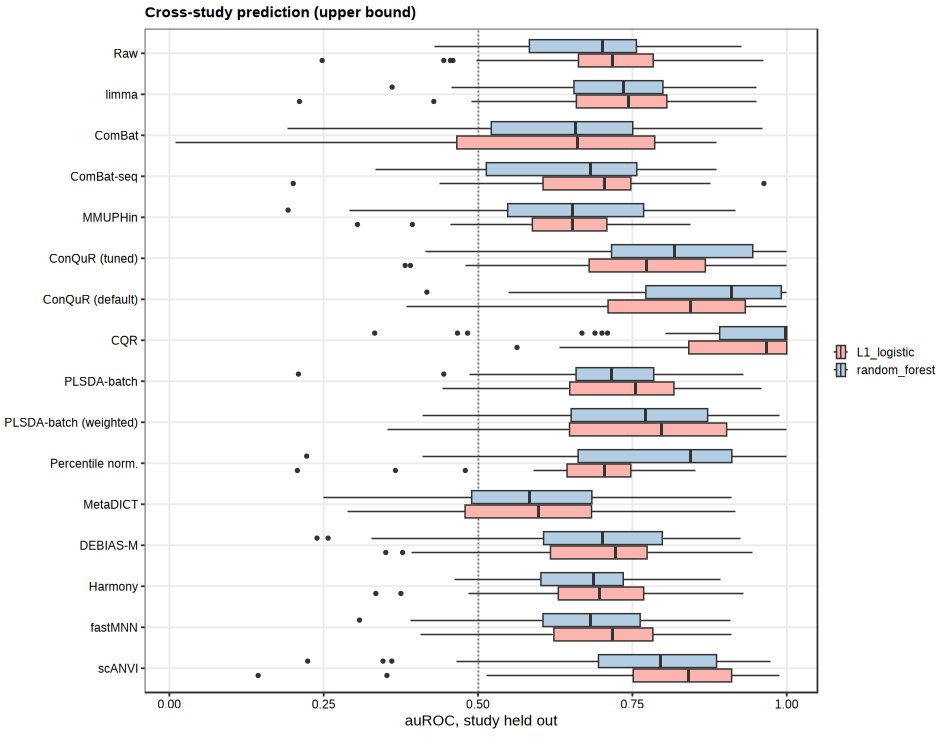

In [6]:
panel_loso <- function(loso, methods_table = method_table()) {
  scored <- loso[loso$status == "ok" & !is.na(loso$auroc), ]
  ggplot(label_methods(scored, methods_table), aes(auroc, label, fill = classifier)) +
    geom_vline(xintercept = 0.5, linetype = "22", linewidth = 0.3, colour = "grey50") +
    geom_boxplot(outlier.size = 0.2, linewidth = 0.25, width = 0.7) +
    scale_fill_brewer(palette = "Pastel1", name = NULL) +
    scale_y_discrete(limits = rev) +
    labs(x = "auROC, study held out", y = NULL,
         title = "Cross-study prediction (upper bound)") +
    theme_bench()
}

show_panel(panel_loso(loso), 100, 78)

## d. Do the three criteria agree on an order?

The direct test of the contradiction in the literature: rank by batch removal, by DA recovery, by cross-study auROC.

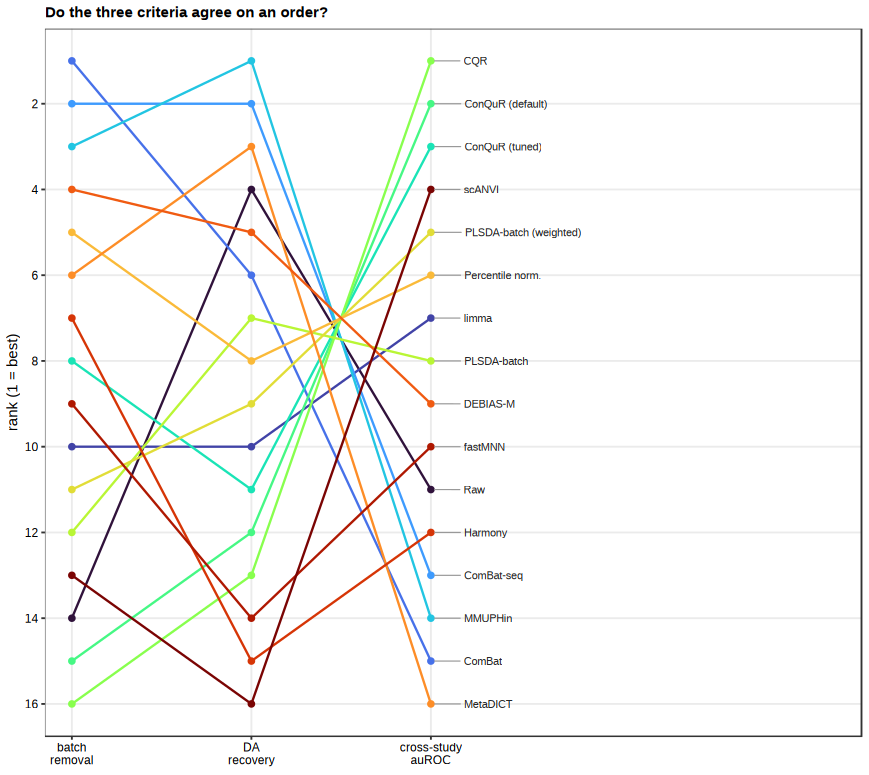

In [7]:
panel_consistency <- function(rankings, methods_table = method_table()) {
  long <- bind_rows(lapply(setdiff(names(rankings), "method"), function(criterion)
    data.frame(method = rankings$method, criterion = criterion,
               rank = rank(-rankings[[criterion]], ties.method = "min"))))
  long$criterion <- factor(long$criterion, setdiff(names(rankings), "method"))
  ggplot(label_methods(long, methods_table), aes(criterion, rank, group = label, colour = label)) +
    geom_line(linewidth = 0.4) + geom_point(size = 1) +
    ggrepel::geom_text_repel(data = ~ subset(.x, as.integer(criterion) == nlevels(criterion)),
                             aes(label = label), size = 1.7, direction = "y", hjust = 0,
                             colour = "grey15", nudge_x = 0.18, segment.size = 0.2,
                             segment.colour = "grey60", max.overlaps = Inf, box.padding = 0.06,
                             point.padding = 0.05, force = 2, min.segment.length = 0, seed = 1) +
    scale_y_reverse(breaks = seq(2, 16, 2)) +
    scale_colour_viridis_d(option = "turbo", guide = "none") +
    scale_x_discrete(expand = expansion(add = c(0.15, 2.4)),
                     labels = function(x) sub(" ", "\n", x)) +
    labs(x = NULL, y = "rank (1 = best)", title = "Do the three criteria agree on an order?") +
    theme_bench()
}

show_panel(panel_consistency(ranking_table(scored, loso)), 92, 82)

## e. What it costs to run

Median seconds against median peak memory; point area is the failure rate. Note the three orders of magnitude on each axis.

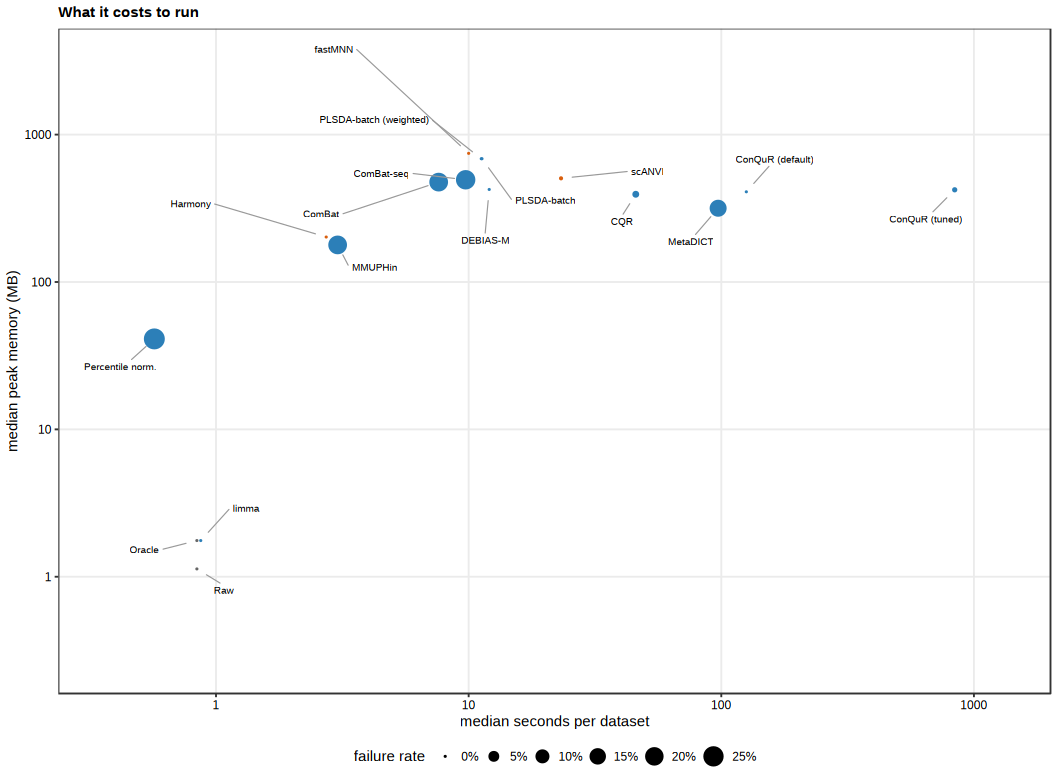

In [8]:
# The permuted-covariate run is a control rather than a method anyone would choose, so it is left
# out of the practicality panel; it stays everywhere its result is the point.
panel_cost <- function(scored, methods_table = method_table()) {
  sensitivity <- methods_table$method[methods_table$role == "sensitivity"]
  cost <- scored[!scored$method %in% sensitivity, ] %>%
    group_by(method) %>%
    summarise(seconds = median(seconds, na.rm = TRUE), memory = median(max_rss_mb, na.rm = TRUE),
              failures = mean(status != "ok"), .groups = "drop")
  ggplot(label_methods(cost, methods_table), aes(seconds, memory)) +
    geom_point(aes(size = failures, colour = track)) +
    ggrepel::geom_text_repel(aes(label = label), size = 1.6, segment.size = 0.2,
                             segment.colour = "grey60", max.overlaps = Inf, force = 30,
                             force_pull = 0.3, box.padding = 0.5, point.padding = 0.3,
                             min.segment.length = 0, max.iter = 50000, seed = 1) +
    scale_x_log10(expand = expansion(mult = 0.12)) +
    scale_y_log10(expand = expansion(mult = 0.3)) +
    scale_size_area(max_size = 4, name = "failure rate", labels = scales::percent) +
    scale_colour_manual(values = track_colours(), guide = "none") +
    guides(size = guide_legend(nrow = 1)) +
    labs(x = "median seconds per dataset", y = "median peak memory (MB)",
         title = "What it costs to run") +
    theme_bench() + theme(legend.position = "bottom")
}

show_panel(panel_cost(scored), 112, 82)

## f. Top three by goal and by design

The recommendation table: what to use, split by research goal and by how confounded the design is.

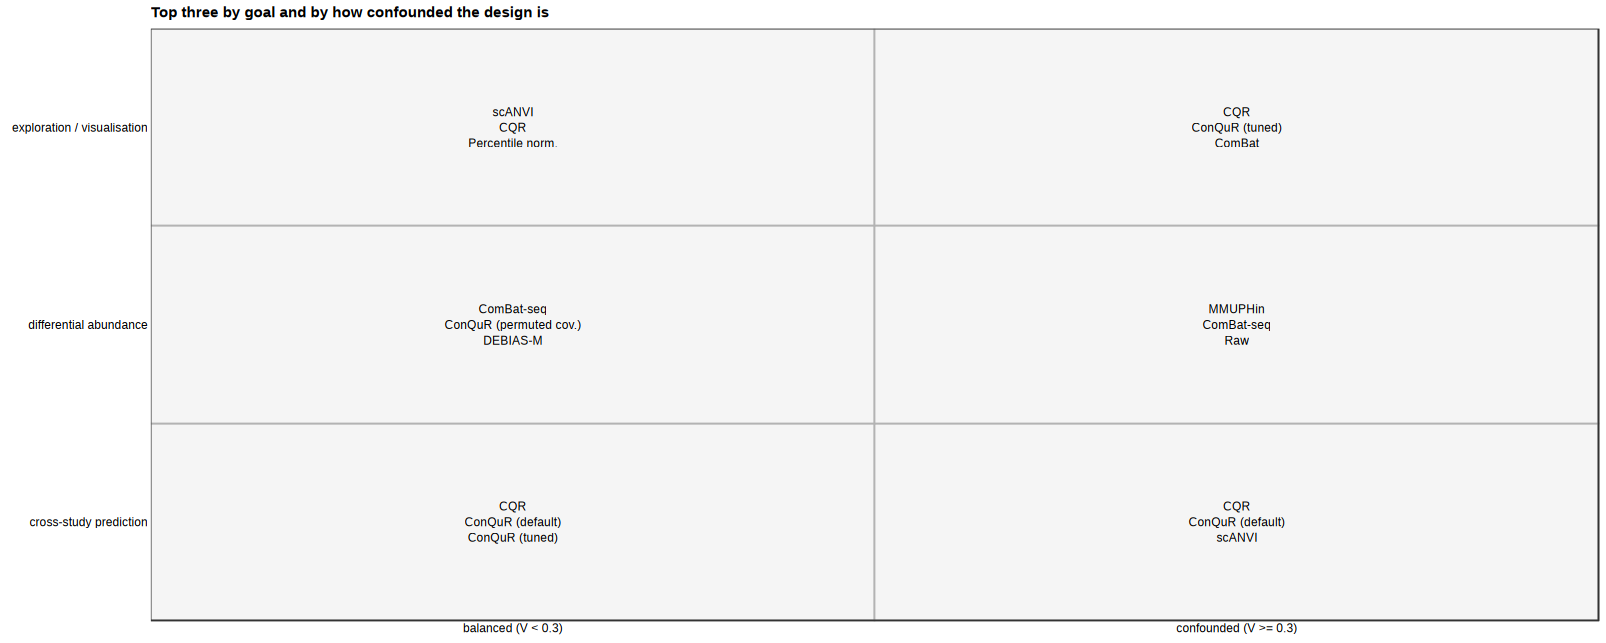

In [9]:
# Top three methods per goal, split at the point where the design stops being balanced.
panel_recommendation <- function(scored, loso, confounding, methods_table = method_table()) {
  evaluated <- scored[scored$status == "ok" & scored$method != "oracle", ]
  evaluated$v <- ifelse(evaluated$regime == "sim", evaluated$cramers_v,
                        confounding[sub("^real/", "", evaluated$dataset)])
  evaluated$design <- ifelse(evaluated$v < 0.3, "balanced (V < 0.3)", "confounded (V >= 0.3)")
  loso$design <- ifelse(confounding[loso$dataset] < 0.3, "balanced (V < 0.3)", "confounded (V >= 0.3)")

  goals <- bind_rows(
    bind_rows(family_score(evaluated, c(batch_metrics(), bio_metrics()),
                           by = c("design", "method"))) %>%
      group_by(design, method) %>%
      summarise(value = mean(score, na.rm = TRUE), goal = "exploration / visualisation", .groups = "drop"),
    evaluated %>% filter(regime == "sim", da_prop > 0) %>% group_by(design, method) %>%
      summarise(value = mean(DA_oracle_AP, na.rm = TRUE), goal = "differential abundance", .groups = "drop"),
    loso %>% filter(status == "ok") %>% group_by(design, method) %>%
      summarise(value = mean(auroc, na.rm = TRUE), goal = "cross-study prediction", .groups = "drop"))

  top <- goals %>% filter(!is.na(value)) %>% group_by(goal, design) %>%
    slice_max(value, n = 3) %>%
    summarise(recommendation = paste(methods_table$label[match(method, methods_table$method)],
                                     collapse = "\n"), .groups = "drop")
  ggplot(top, aes(design, goal)) +
    geom_tile(fill = "grey96", colour = "grey70", linewidth = 0.3) +
    geom_text(aes(label = recommendation), size = 2, lineheight = 1.1) +
    scale_x_discrete(expand = expansion(0)) + scale_y_discrete(expand = expansion(0)) +
    labs(x = NULL, y = NULL, title = "Top three by goal and by how confounded the design is") +
    theme_bench() + theme(panel.grid = element_blank(), axis.ticks = element_blank())
}

show_panel(panel_recommendation(scored, loso, confounding), 170, 68)

## Assembled figure

Everything above, in the layout that goes to the journal: 180 x 240 mm, one page.
The panels shrink here — that is the real submission size, and the font sizes above were
chosen for it.

wrote results/figures/fig5.pdf (180 x 240 mm)


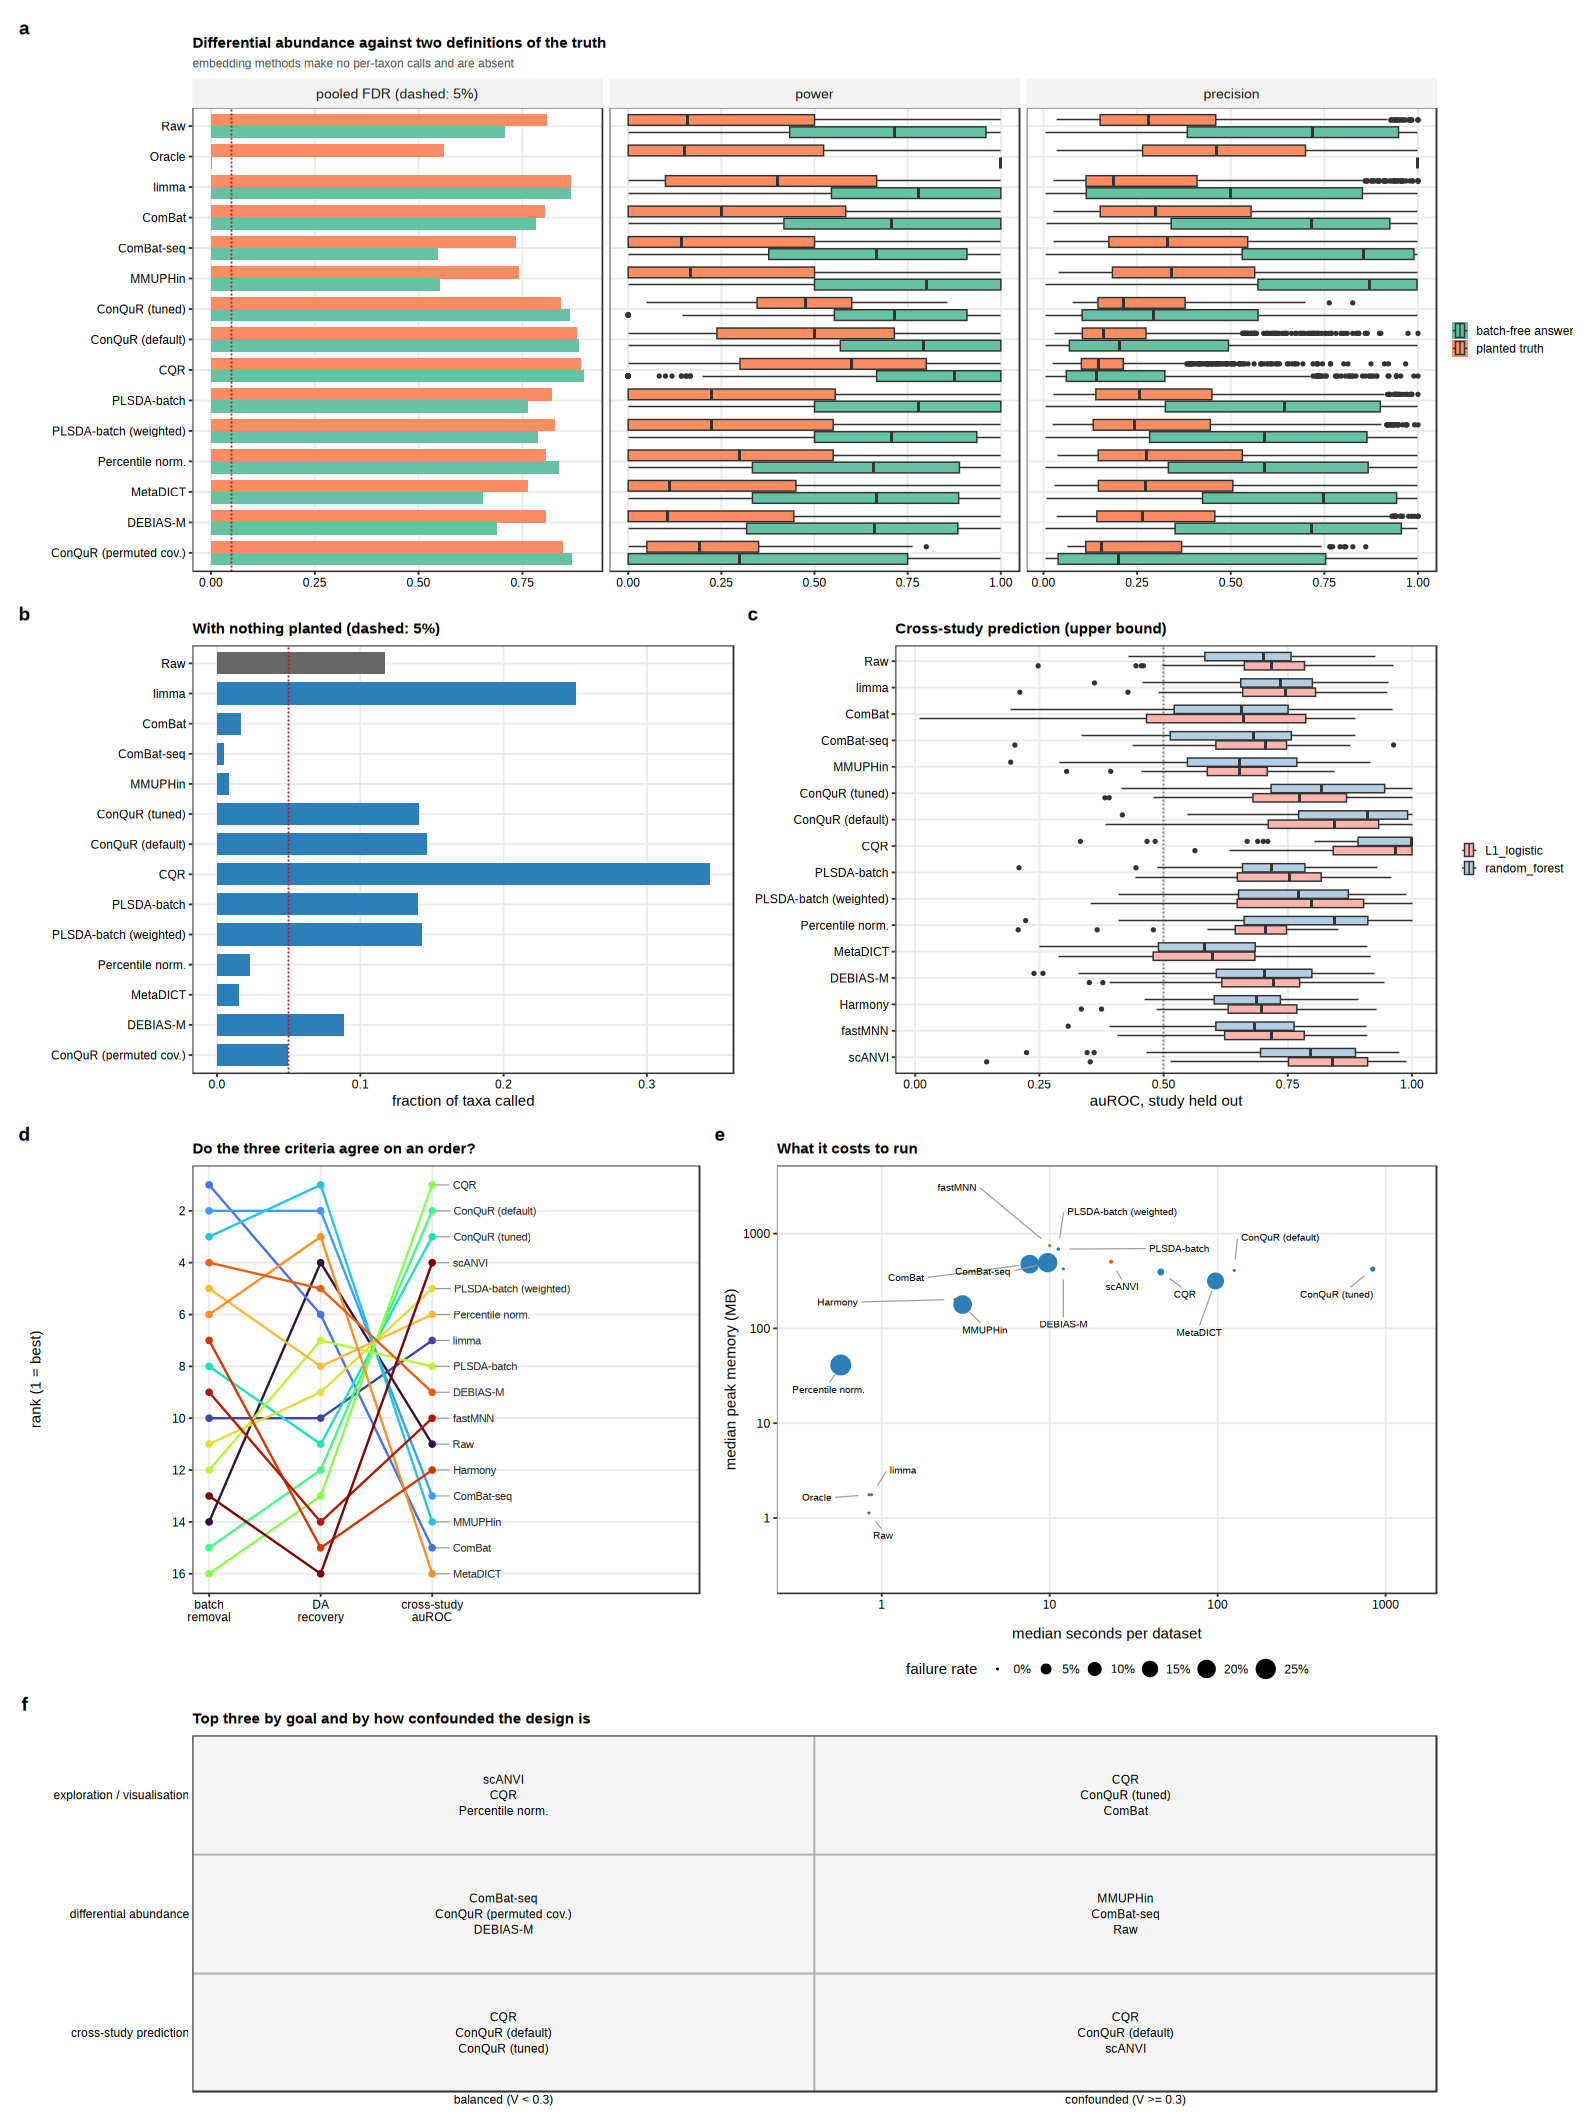

In [10]:
figure <- (panel_da(simulated[simulated$da_prop > 0, ]) /
           (panel_null_da(simulated[simulated$da_prop == 0 & simulated$method != "oracle", ]) |
            panel_loso(loso)) /
           ((panel_consistency(ranking_table(scored, loso)) | panel_cost(scored)) +
            plot_layout(widths = c(1, 1.3))) /
           panel_recommendation(scored, loso, confounding)) +
  plot_layout(heights = c(1.3, 1.2, 1.2, 1)) +
  plot_annotation(tag_levels = "a") &
  theme(plot.tag = element_text(size = 9, face = "bold"))

save_figure(figure, "results/figures/fig5.pdf", 180, 240)
show_panel(figure, 180, 240, scale = 1.5)